# Taller 2

Hecho por Simón Fajardo y Diego Céspedes
18/10/2026

### Comprensión del Dataset

In [3]:
%pip install pandas numpy matplotlib seaborn

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     -------------- ----------------------- 30.7/80.3 kB 660.6 kB/s eta 0:00:01
     --------------------------------- ---- 71.7/80.3 kB 787.7 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 897.7 kB/s eta 0:00:00
     ---------------------------------------- 0.0/139.8 kB ? eta -:--:--
     ------------------------------ ------- 112.6/139.8 kB 6.4 MB/s eta 0:00:01
     -------------------------------------- 139.8/139.8 kB 2.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB 7.9 MB/s eta 0:00:02
   -- ------------------------------------- 0.5/9.7 MB 5.2 MB/s eta 0:00:02
   --- ------------------------------------ 0.8/9.7 MB 5.9 MB/s eta 0:00:02
   ---- ----------------------------------- 1.1/9.7 MB 5.9 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/9.7 MB 7.4 MB/s eta 0:00:02
   ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Mall_Customers.csv')
df.head()

print("Dimensiones:", df.shape)
print("\nTipos de dato (pandas):")
print(df.dtypes)
print("\nValores nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("IDs únicos:", df["CustomerID"].nunique())

Matplotlib is building the font cache; this may take a moment.


Dimensiones: (200, 5)

Tipos de dato (pandas):
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Valores nulos por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Filas duplicadas: 0
IDs únicos: 200


                       Tipo pandas  \
CustomerID                   int64   
Gender                         str   
Age                          int64   
Annual Income (k$)           int64   
Spending Score (1-100)       int64   

                                                         Tipo estadístico  
CustomerID                   Identificador (nominal, sin valor analítico)  
Gender                                         Categórica nominal binaria  
Age                                      Numérica discreta (años enteros)  
Annual Income (k$)      Numérica continua (registrada en miles de USD,...  
Spending Score (1-100)         Numérica ordinal/discreta acotada [1, 100]  
       CustomerID     Age  Annual Income (k$)  Spending Score (1-100)
count      200.00  200.00              200.00                  200.00
mean       100.50   38.85               60.56                   50.20
std         57.88   13.97               26.26                   25.82
min          1.00   18.00          

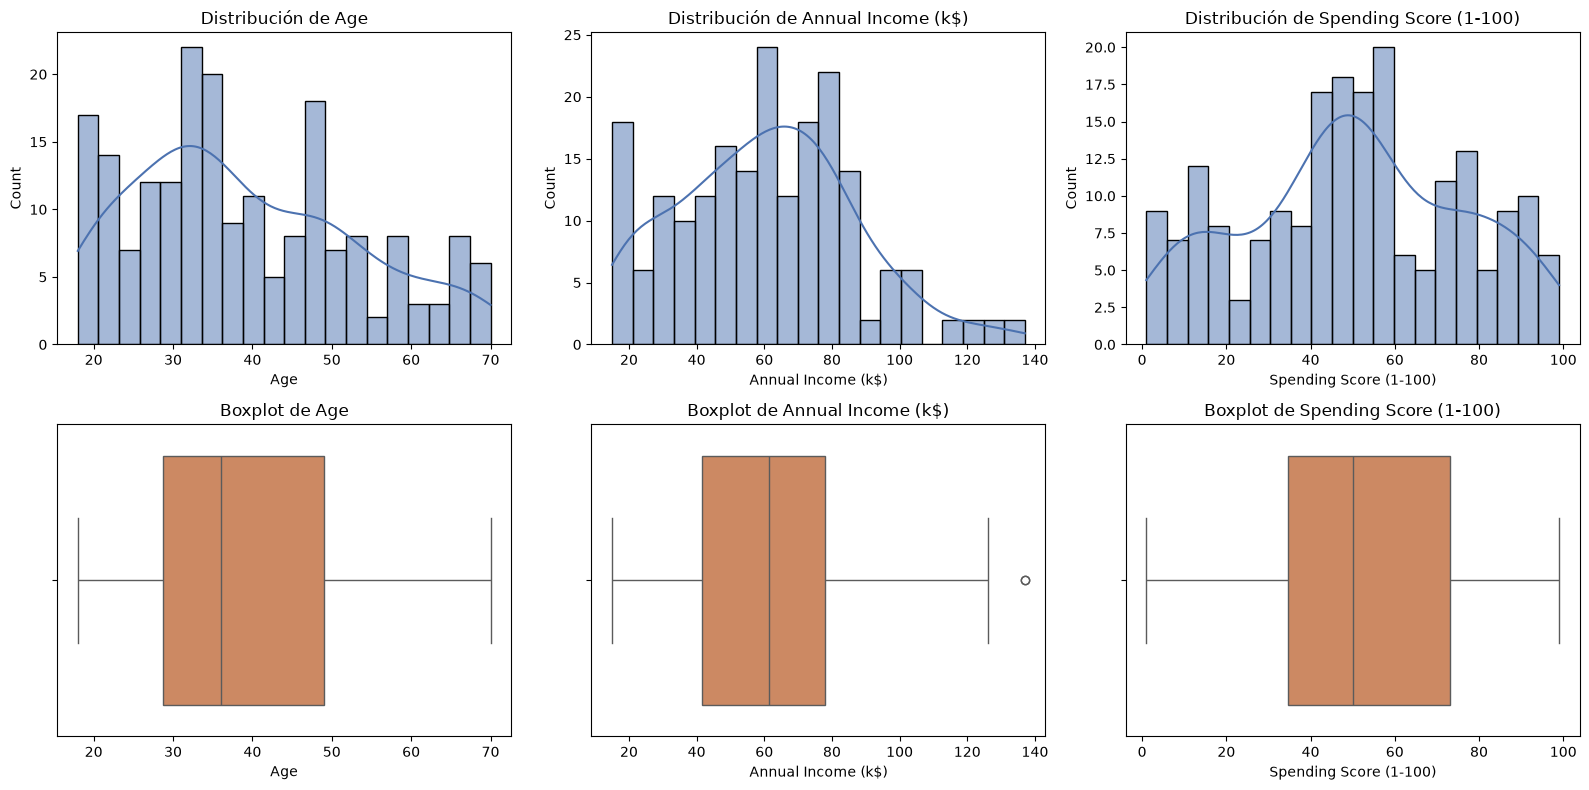

Asimetría (skewness):
Age                       0.486
Annual Income (k$)        0.322
Spending Score (1-100)   -0.047
dtype: float64


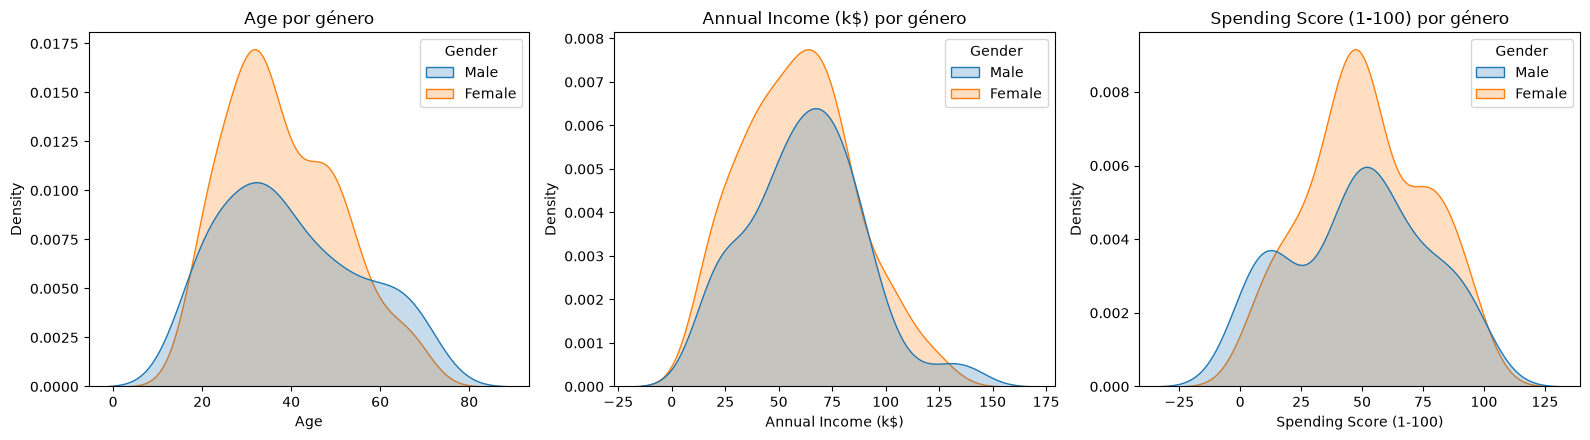

         Age  Annual Income (k$)  Spending Score (1-100)
Gender                                                  
Female  38.1                59.2                    51.5
Male    39.8                62.2                    48.5


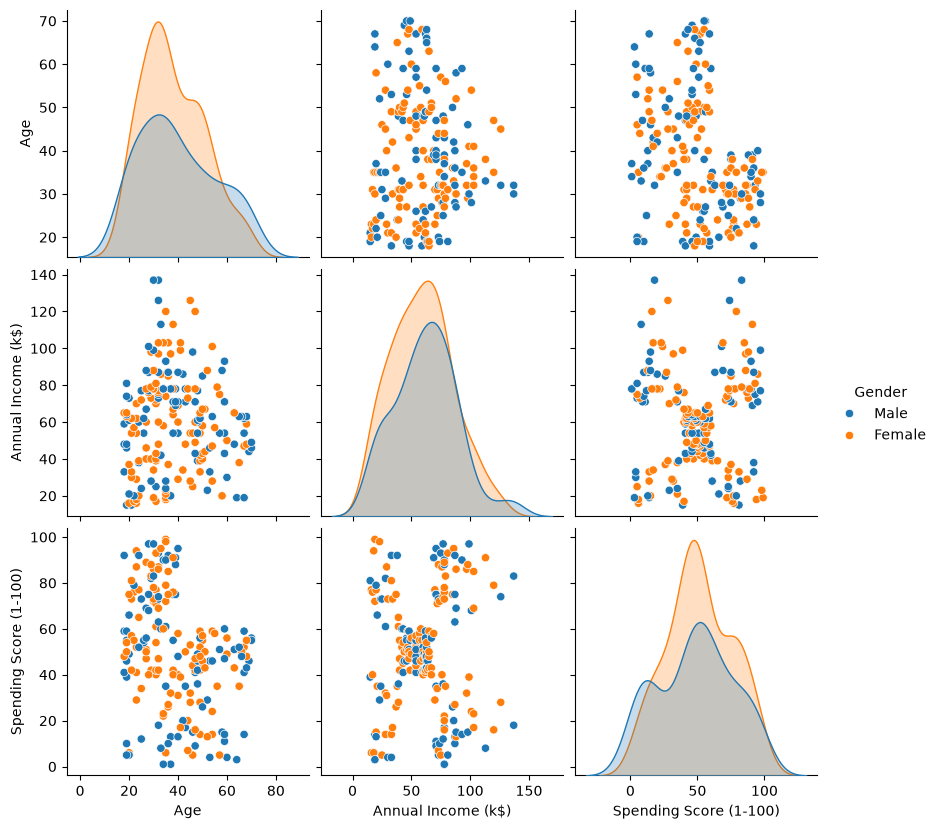

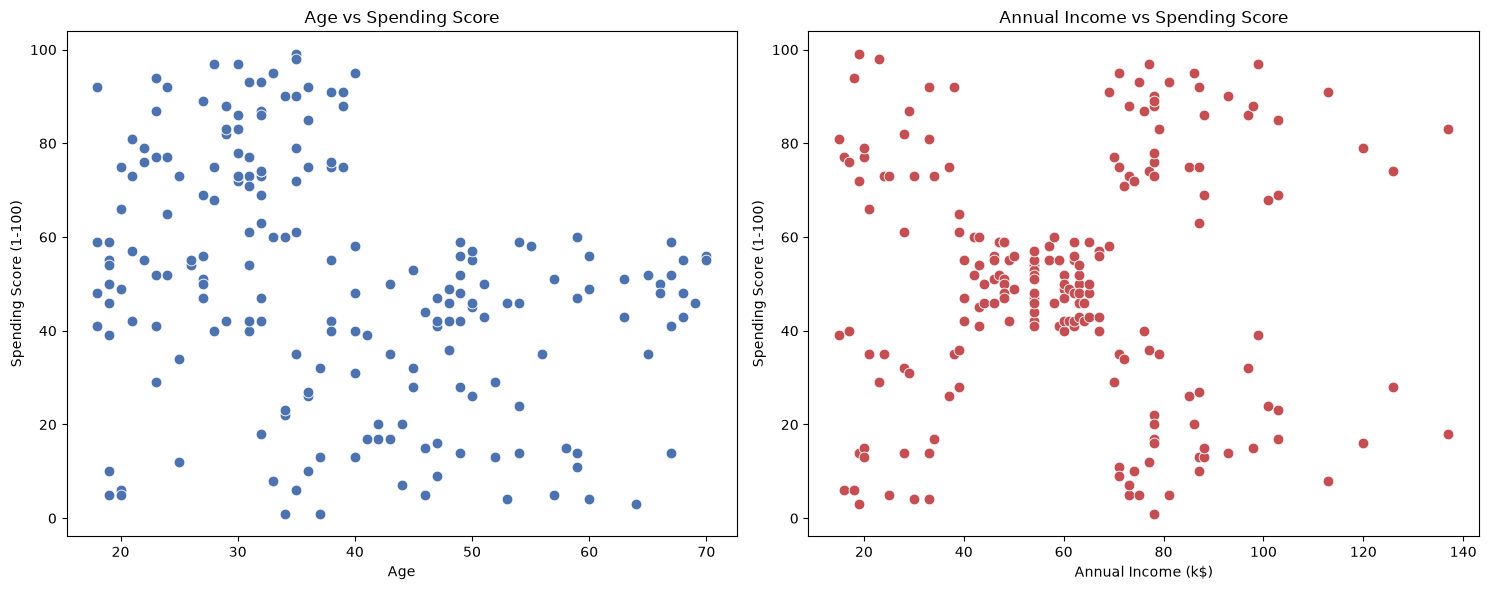

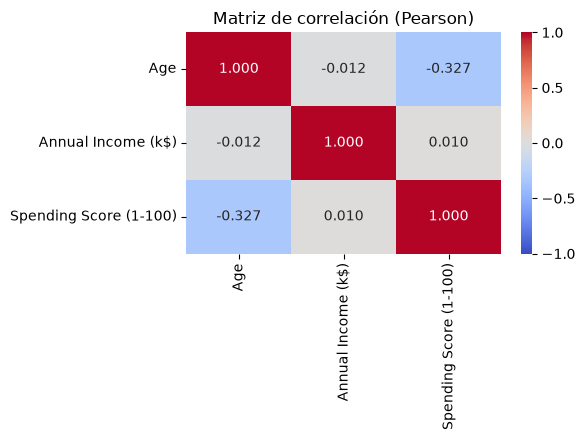

In [ ]:
# Clasificación estadística de cada variable
tipos = pd.DataFrame({
    "Tipo pandas": df.dtypes.astype(str),
    "Tipo estadístico": [
        "Identificador (nominal, sin valor analítico)",
        "Categórica nominal binaria",
        "Numérica discreta (años enteros)",
        "Numérica continua (registrada en miles de USD, redondeada)",
        "Numérica ordinal/discreta acotada [1, 100]"
    ]
})
print(tipos)
 
print(df.describe().round(2))
 
print(df["Gender"].value_counts())
print((df["Gender"].value_counts(normalize=True) * 100).round(1))
 
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
 
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, bins=20, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"Distribución de {col}")
    sns.boxplot(x=df[col], ax=axes[1, i], color="#DD8452")
    axes[1, i].set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.savefig("fig1_distribuciones.png", dpi=150)
plt.show()
 
print("Asimetría (skewness):")
print(df[num_cols].skew().round(3))
 
# Distribución por género
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, col in enumerate(num_cols):
    sns.kdeplot(data=df, x=col, hue="Gender", fill=True, ax=axes[i])
    axes[i].set_title(f"{col} por género")
plt.tight_layout()
plt.savefig("fig2_por_genero.png", dpi=150)
plt.show()
print(df.groupby("Gender")[num_cols].mean().round(1))
 
sns.pairplot(df.drop(columns="CustomerID"), hue="Gender", diag_kind="kde", height=2.8)
plt.savefig("fig3_pairplot.png", dpi=150)
plt.show()
 
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=df, x="Age", y="Spending Score (1-100)", ax=axes[0], s=60, color="#4C72B0")
axes[0].set_title("Age vs Spending Score")
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", ax=axes[1], s=60, color="#C44E52")
axes[1].set_title("Annual Income vs Spending Score")
plt.tight_layout()
plt.savefig("fig4_scatters.png", dpi=150)
plt.show()
 
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (Pearson)")
plt.tight_layout()
plt.savefig("fig5_correlacion.png", dpi=150)
plt.show()